# Optimizers Comparison
## Retail Store Profit Prediction – Polynomial Regression

This notebook compares the five optimizers implemented in the project:

1. Gradient Descent with Momentum
2. Stochastic Gradient Descent (SGD)
3. Mini-Batch Gradient Descent
4. RMSProp
5. Adam

**Important:** The values in this notebook are transcribed from the saved output cells of the five project notebooks. This notebook compares the recorded runs; it does not retrain the models.


## 1. Comparison Dataset and Model

All five notebooks use the same Superstore dataset, the same three input features (`Sales`, `Quantity`, `Discount`), the same target (`Profit`), degree-2 polynomial features, and the same 80/20 train-test split with `random_state=42`.

The recorded optimizer settings are not identical: the notebooks use different epoch counts and learning rates. Therefore, the results below describe the performance of these particular runs, not a perfectly controlled comparison under equal training budgets.


## 2. Enter the Recorded Results

The following values are taken from the evaluation outputs saved in the individual notebooks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = pd.DataFrame({
    "Optimizer": [
        "GD + Momentum",
        "SGD",
        "Mini-Batch GD",
        "RMSProp",
        "Adam"
    ],
    "Epochs": [1000, 100, 200, 1000, 1000],
    "Learning Rate": [0.01, 0.001, 0.01, 0.01, 0.01],
    "Final Training Loss": [
        0.40654858535215804,
        0.20782058560463598,
        0.2591000278163203,
        0.15348268516064537,
        0.18009844008253825
    ],
    "MSE": [
        44086.2004484165,
        37821.93812108382,
        41742.368998522536,
        30113.210809716653,
        25439.870317289813
    ],
    "RMSE": [
        209.96714135410926,
        194.47863152820625,
        204.309493167896,
        173.53158447301936,
        159.49880976762745
    ],
    "MAE": [
        67.16966135344205,
        51.8410748738194,
        56.80183231076374,
        44.73249191681663,
        45.964047534668794
    ],
    "R2 Score": [
        0.09072731576407145,
        0.21992698738912697,
        0.1390685629608056,
        0.37891857893376424,
        0.47530567536475277
    ]
})

display(results.style.format({
    "Learning Rate": "{:.4f}",
    "Final Training Loss": "{:.4f}",
    "MSE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "MAE": "{:,.2f}",
    "R2 Score": "{:.4f}"
}))


,Optimizer,Epochs,Learning Rate,Final Training Loss,MSE,RMSE,MAE,R2 Score
0,GD + Momentum,1000,0.0100,0.4065,"44,086.20",209.97,67.17,0.0907
1,SGD,100,0.0010,0.2078,"37,821.94",194.48,51.84,0.2199
2,Mini-Batch GD,200,0.0100,0.2591,"41,742.37",204.31,56.80,0.1391
3,RMSProp,1000,0.0100,0.1535,"30,113.21",173.53,44.73,0.3789
4,Adam,1000,0.0100,0.1801,"25,439.87",159.50,45.96,0.4753


## 3. Compare Test-Set Error: RMSE

RMSE measures the typical size of prediction errors in the original target units. Lower RMSE is better.

The lowest recorded RMSE belongs to the optimizer with the smallest bar.

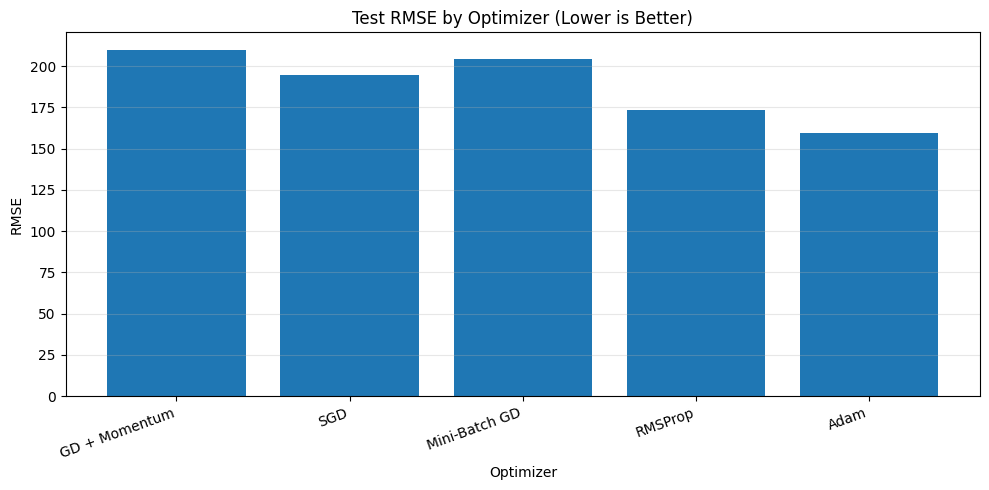

In [2]:
plt.figure(figsize=(10, 5))
plt.bar(results["Optimizer"], results["RMSE"])
plt.title("Test RMSE by Optimizer (Lower is Better)")
plt.xlabel("Optimizer")
plt.ylabel("RMSE")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Compare Mean Absolute Error: MAE

MAE is the average absolute difference between actual and predicted profit. Lower MAE is better.

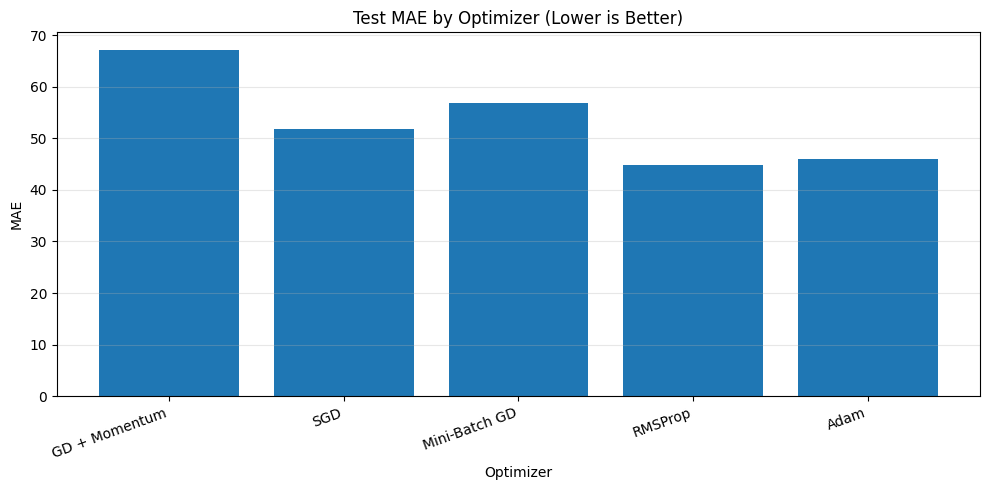

In [3]:
plt.figure(figsize=(10, 5))
plt.bar(results["Optimizer"], results["MAE"])
plt.title("Test MAE by Optimizer (Lower is Better)")
plt.xlabel("Optimizer")
plt.ylabel("MAE")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Compare R² Score

R² describes how much of the variation in the test target is explained by the model. A higher value is generally better. A value below 1 does not mean the model is accurate enough for every business use.

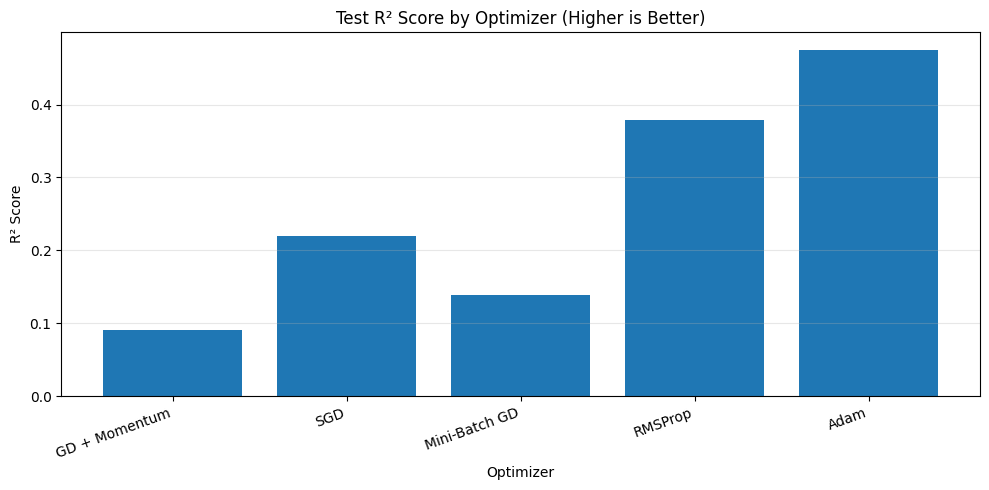

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(results["Optimizer"], results["R2 Score"])
plt.title("Test R² Score by Optimizer (Higher is Better)")
plt.xlabel("Optimizer")
plt.ylabel("R² Score")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Compare MSE

MSE is the average squared prediction error. It penalizes larger errors more strongly than MAE. Lower MSE is better.

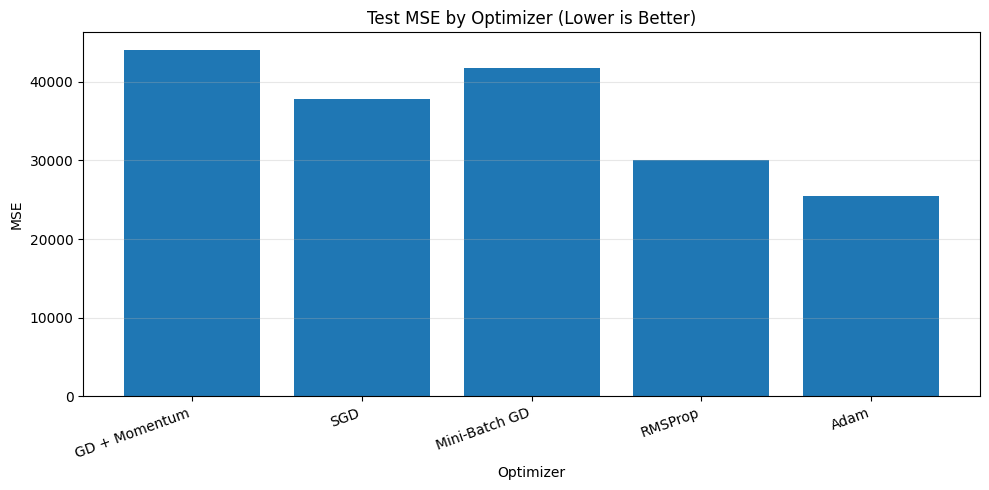

In [5]:
plt.figure(figsize=(10, 5))
plt.bar(results["Optimizer"], results["MSE"])
plt.title("Test MSE by Optimizer (Lower is Better)")
plt.xlabel("Optimizer")
plt.ylabel("MSE")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Rank the Recorded Runs

The next table ranks the saved runs by RMSE. This is a ranking of the current recorded experiments only; because the hyperparameters and epoch counts differ, it should not be interpreted as a definitive ranking of the optimizers in general.

In [6]:
ranking = results.sort_values("RMSE", ascending=True).reset_index(drop=True)
ranking.insert(0, "RMSE Rank", range(1, len(ranking) + 1))

display(ranking[[
    "RMSE Rank", "Optimizer", "RMSE", "MAE", "R2 Score", "Final Training Loss"
]].style.format({
    "RMSE": "{:,.2f}",
    "MAE": "{:,.2f}",
    "R2 Score": "{:.4f}",
    "Final Training Loss": "{:.4f}"
}))


,RMSE Rank,Optimizer,RMSE,MAE,R2 Score,Final Training Loss
0,1,Adam,159.50,45.96,0.4753,0.1801
1,2,RMSProp,173.53,44.73,0.3789,0.1535
2,3,SGD,194.48,51.84,0.2199,0.2078
3,4,Mini-Batch GD,204.31,56.80,0.1391,0.2591
4,5,GD + Momentum,209.97,67.17,0.0907,0.4065


## 8. Best Recorded Results

This cell identifies the best recorded optimizer according to RMSE, MAE, and R² separately. Different metrics can select different optimizers.

In [7]:
best_rmse = results.loc[results["RMSE"].idxmin()]
best_mae = results.loc[results["MAE"].idxmin()]
best_r2 = results.loc[results["R2 Score"].idxmax()]

print("Best recorded RMSE:", best_rmse["Optimizer"], "-", round(best_rmse["RMSE"], 2))
print("Best recorded MAE:", best_mae["Optimizer"], "-", round(best_mae["MAE"], 2))
print("Best recorded R2:", best_r2["Optimizer"], "-", round(best_r2["R2 Score"], 4))


Best recorded RMSE: Adam - 159.5
Best recorded MAE: RMSProp - 44.73
Best recorded R2: Adam - 0.4753


## 9. Interpretation of the Current Results

Based on the saved notebook outputs:

- **Adam** has the lowest RMSE (159.50) and the highest R² (0.4753) in these recorded runs.
- **RMSProp** has the lowest MAE (44.73).
- Gradient Descent with Momentum has the highest RMSE and lowest R² among these five recorded runs.
- The results show that the optimizer with the best result can depend on the evaluation metric.

The current best R² is about 0.475, meaning the Adam model explains approximately 47.53% of the variation in test-set profit for this experiment. This is a moderate result, not a guarantee of high predictive accuracy.


## 10. Important Limitations and Next Step: Fair Experiment

The current comparison is useful as a summary of the runs already completed, but it is not a fully controlled optimizer benchmark because:

1. The epoch counts differ (100, 200, and 1000).
2. Learning rates differ (0.001 for SGD and 0.01 for the others).
3. The loss histories are recorded at slightly different points in the update cycle in some notebooks.
4. RMSProp and Adam use full-batch gradients in these implementations, while SGD and Mini-Batch use one-example and mini-batch updates.

For a fairer experiment, rerun all optimizers using a documented, comparable training budget, consistent loss logging, and the same train/test split and preprocessing. For stochastic methods, repeat runs with multiple random seeds and report average and variation.

This notebook intentionally preserves the original recorded values rather than silently changing or recomputing them.


## 11. Conclusion

This notebook brings together the recorded evaluation results of all five optimizers. Adam performs best on RMSE and R² in the current saved runs, while RMSProp performs best on MAE.

The comparison is a summary of the current experiments. A controlled rerun is recommended before making a definitive claim that one optimizer is universally better than the others.